# Análisis de ventas de videojuegos: ¿qué hace exitoso a un juego?

*Proyecto de Bootcamp – TripleTen (Sprint 6, proyecto integrado). Ice es una tienda online simulada; los datos son públicos, modificados por TripleTen.*

**Objetivo:** identificar los patrones que determinan si un videojuego tiene éxito o no, usando datos históricos hasta 2016, para planificar la campaña publicitaria de 2017 y detectar proyectos prometedores.

**Estructura del notebook:**
1. Carga y estudio general de los datos
2. Preparación de los datos
3. Análisis exploratorio de datos
4. Perfil de usuario por región
5. Prueba de hipótesis
6. Conclusión general


## Resumen ejecutivo

- **Datos:** 16.715 videojuegos con ventas por región, puntuaciones de crítica y usuarios y clasificación ESRB. Por el ciclo de vida de las plataformas (≈9-10 años), el análisis se centra en **2013-2016** (2.233 juegos).
- **Plataformas:** PS4 lidera las ventas del período (314,14 M), seguida de PS3 (181,43 M) y XOne (159,32 M). PS4 y XOne son las plataformas con proyección para 2017; PS3, X360 y WiiU van de salida.
- **Reseñas:** la puntuación de la crítica se correlaciona con las ventas (**0,41** en PS4) y la de los usuarios casi nada (**−0,03**). El patrón se repite en las 6 plataformas principales (crítica: 0,33-0,41).
- **Géneros:** Action vende más en total (321,87 M, 766 títulos), pero Shooter tiene la mayor venta media por título (**1,25 M** frente a 0,42 M de Action).
- **Regiones:** en Norteamérica dominan PS4 (24,8 %) y XOne (21,3 %); en Japón, 3DS (48,2 %) y el género RPG (36,3 %).
- **Hipótesis (α = 0,05, prueba de Welch):** no hay diferencia significativa en la puntuación de usuarios entre XOne y PC (p = 0,148); sí la hay entre Action y Sports (6,84 vs. 5,24; p < 0,0001).
- **Recomendación:** concentrar la campaña de 2017 en Action/Shooter/Sports para PS4 y XOne en Norteamérica y Europa, con una estrategia propia para Japón (RPG, Nintendo/Sony), y priorizar la prensa especializada sobre las reseñas de usuarios.

## Paso 1. Carga y estudio general de los datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

df = pd.read_csv('data/games.csv')
df.head(10)

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


In [3]:
df.describe(include='all')

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
count,16713,16715,16446.000000,16713,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000,10014,9949
unique,11559,31,NaN,12,NaN,NaN,NaN,NaN,NaN,96,8
top,Need for Speed: Most Wanted,PS2,NaN,Action,NaN,NaN,NaN,NaN,NaN,tbd,E
freq,12,2161,NaN,3369,NaN,NaN,NaN,NaN,NaN,2424,3990
mean,NaN,NaN,2006.484616,NaN,0.263377,0.145060,0.077617,0.047342,68.967679,NaN,NaN
std,NaN,NaN,5.877050,NaN,0.813604,0.503339,0.308853,0.186731,13.938165,NaN,NaN
min,NaN,NaN,1980.000000,NaN,0.000000,0.000000,0.000000,0.000000,13.000000,NaN,NaN
25%,NaN,NaN,2003.000000,NaN,0.000000,0.000000,0.000000,0.000000,60.000000,NaN,NaN
50%,NaN,NaN,2007.000000,NaN,0.080000,0.020000,0.000000,0.010000,71.000000,NaN,NaN
75%,NaN,NaN,2010.000000,NaN,0.240000,0.110000,0.040000,0.030000,79.000000,NaN,NaN


A simple vista, esto es lo que hay que arreglar antes de poder analizar nada en serio: el dataset tiene 16,715 filas y 11 columnas, pero los nombres vienen en `CamelCase` (`Year_of_Release`, `User_Score`...), así que lo primero es bajarlos a minúsculas para trabajar más cómodo. `Year_of_Release` está como `float64` cuando en realidad es un año, o sea que debería ser un entero. `User_Score` es texto en vez de número, y sospecho que es porque mezcla calificaciones reales con el valor `'tbd'`. Y hay huecos (valores ausentes) en varias columnas: `Name`, `Year_of_Release`, `Genre`, `Critic_Score`, `User_Score` y `Rating`.

## Paso 2. Preparación de los datos

### 2.1 Nombres de columnas en minúsculas

In [4]:
df.columns = df.columns.str.lower()
df.columns

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='str')

### 2.2 Filas sin nombre ni género

Solo hay 2 filas sin `name` (y por lo tanto sin `genre`, ya que dependen del mismo registro origen). Al tratarse de una fracción mínima del dataset (0.01%) y no poder inferir esta información, las eliminamos.

In [5]:
df[df['name'].isna()]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,NaN,GEN,1993.0,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993.0,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN


In [6]:
df = df.dropna(subset=['name']).reset_index(drop=True)
df.shape

(16713, 11)

### 2.3 Conversión de tipos de datos

`year_of_release` lo paso a `Int64` (la versión de entero que sí admite nulos), porque un año no tiene sentido con decimales. Los que están ausentes los dejo como `<NA>` en vez de inventarles una fecha — son apenas un 1.6% del dataset, y no tengo forma confiable de adivinar cuándo salió cada uno.

Con `user_score` confirmo lo que sospechaba: el texto `'tbd'` aparece mezclado con los números, y significa "to be determined" — es decir, la reseña de usuarios todavía no estaba lista cuando se armó este dataset. Así que no es realmente una puntuación, es la ausencia de una. Lo reemplazo por `NaN` y ahí sí puedo convertir la columna entera a `float64`.

In [7]:
df['year_of_release'] = df['year_of_release'].astype('Int64')

print("Valores 'tbd' en user_score:", (df['user_score'] == 'tbd').sum())
df['user_score'] = df['user_score'].replace('tbd', np.nan).astype(float)

df.dtypes

Valores 'tbd' en user_score: 2424


name                   str
platform               str
year_of_release      Int64
genre                  str
na_sales           float64
eu_sales           float64
jp_sales           float64
other_sales        float64
critic_score       float64
user_score         float64
rating                 str
dtype: object

### 2.4 Valores ausentes

Antes de seguir, vale la pena pensar por qué falta lo que falta, en vez de simplemente rellenar y seguir:

`year_of_release` tiene 269 nulos. Me imagino que son juegos antiguos o de nicho que la fuente original nunca registró con fecha. Los dejo en blanco; ponerles una fecha inventada solo ensuciaría cualquier análisis por año.

`critic_score` y `user_score` tienen muchísimos más nulos, sobre todo en juegos viejos o de plataformas menos populares. Lo más probable es que esos juegos simplemente nunca fueron reseñados — sitios como Metacritic no cubrían todo, especialmente antes de los 2000. Rellenar esto con la media o la mediana estaría inventando una opinión que nadie dio, así que los dejo como `NaN` y uso `dropna()` solo cuando el cálculo puntual lo necesita.

`rating` también tiene muchos vacíos: significa que el juego nunca fue clasificado por la ESRB, algo común en juegos muy antiguos (la ESRB se fundó en 1994) o de plataformas fuera de EE. UU./Europa. Ojo con no confundir esto con "sin restricción de edad" — son cosas distintas.

No hago ningún relleno global de nulos. Cada análisis usa `dropna()` solo sobre las columnas que necesita, para no perder datos de más en otras partes.

In [8]:
df.isna().sum()

name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating             6764
dtype: int64

### 2.5 Ventas totales por juego

In [9]:
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']
df[['name', 'platform', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'total_sales']].head()

,name,platform,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,Wii,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,NES,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,Wii,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,GB,11.27,8.89,10.22,1.00,31.38


## Paso 3. Análisis exploratorio de datos

### 3.1 Juegos lanzados por año

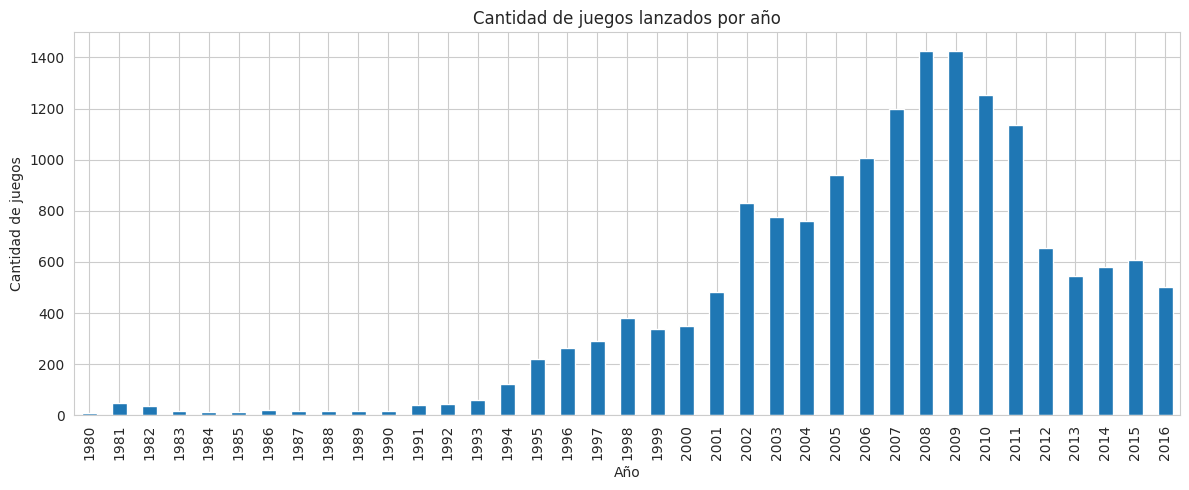

In [10]:
games_per_year = df.groupby('year_of_release')['name'].count()

plt.figure(figsize=(12,5))
games_per_year.plot(kind='bar')
plt.title('Cantidad de juegos lanzados por año')
plt.xlabel('Año')
plt.ylabel('Cantidad de juegos')
plt.tight_layout()
plt.show()

Antes de mediados de los 90 hay muy pocos juegos por año (apenas unas decenas), así que esos datos casi no sirven para entender el mercado actual. A partir del 2000 los lanzamientos se disparan, llegan a su punto más alto alrededor de 2008-2009 y después empiezan a bajar. Y ojo: **2016 está incompleto** (el propio enunciado lo advierte), así que tampoco puedo tomarlo como un año "cerrado" para sacar tendencias.

### 3.2 Ventas por plataforma a lo largo del tiempo

In [11]:
platform_total_sales = df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
top_platforms = platform_total_sales.head(10)
top_platforms

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64

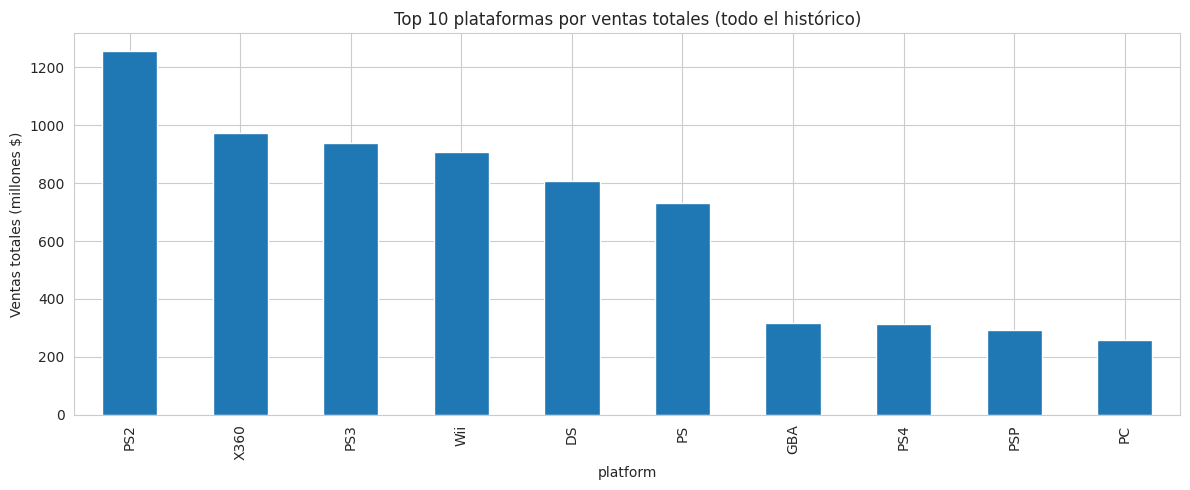

In [12]:
plt.figure(figsize=(12,5))
top_platforms.plot(kind='bar')
plt.title('Top 10 plataformas por ventas totales (todo el histórico)')
plt.ylabel('Ventas totales (millones $)')
plt.tight_layout()
plt.show()

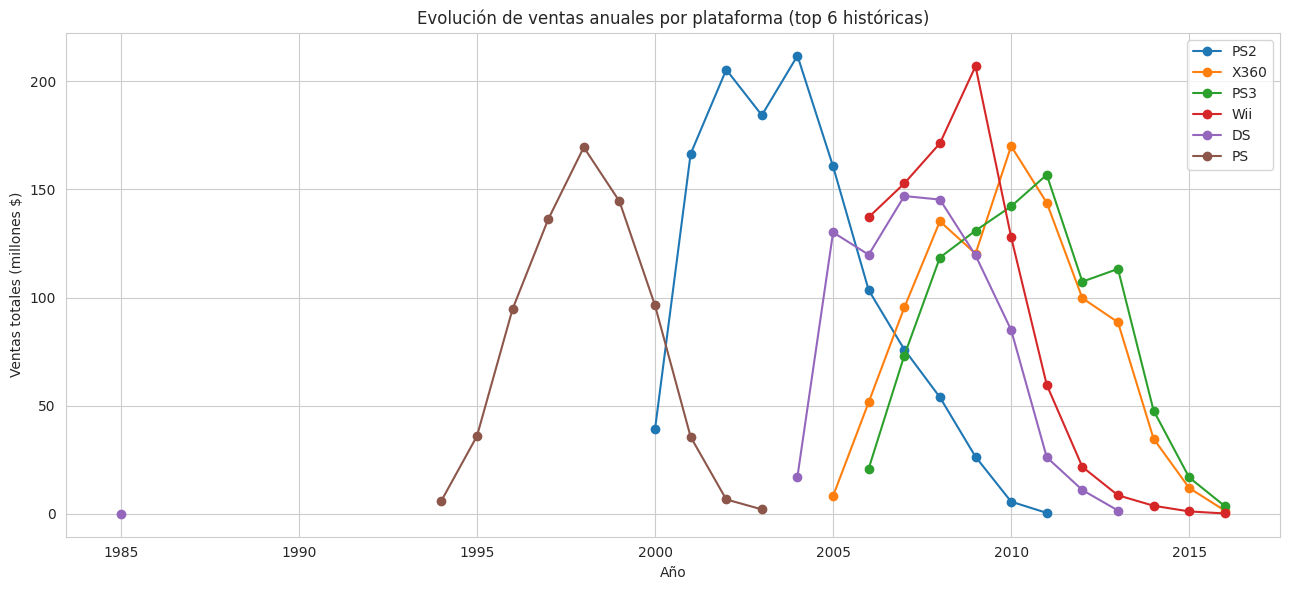

In [13]:
top6 = top_platforms.head(6).index
pivot = df[df['platform'].isin(top6)].pivot_table(
    index='year_of_release', columns='platform', values='total_sales', aggfunc='sum'
)

plt.figure(figsize=(13,6))
for p in top6:
    plt.plot(pivot.index, pivot[p], marker='o', label=p)
plt.title('Evolución de ventas anuales por plataforma (top 6 históricas)')
plt.xlabel('Año')
plt.ylabel('Ventas totales (millones $)')
plt.legend()
plt.tight_layout()
plt.show()

**Sobre el ciclo de vida de una plataforma:** el patrón se ve clarísimo en forma de campana — una consola tarda 1-2 años en despegar después de salir al mercado, llega a su pico de ventas unos 3-4 años después, y luego decae en otros 2-3 años cuando llega la siguiente generación. En total, de principio a fin, una plataforma dura activa unos 9-10 años. Se nota bien con PS2, Wii, DS o X360: fueron líderes absolutas en su momento y hoy prácticamente no venden nada.

### 3.3 Elección del período relevante para el modelo 2017

Si una plataforma dura activa alrededor de una década, y las consolas que importan para 2017 son las de la generación actual (PS4, XOne, 3DS, PC, WiiU), entonces tiene sentido quedarme con **2013-2016**. Es una ventana suficientemente amplia para ver tendencias reales, pero deja fuera generaciones ya muertas que solo meterían ruido al modelo.

In [14]:
df_recent = df[(df['year_of_release'] >= 2013) & (df['year_of_release'] <= 2016)].copy()
df_recent.shape

(2233, 12)

### 3.4 Plataformas líderes en el período relevante

In [15]:
platform_sales_recent = df_recent.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
platform_sales_recent

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

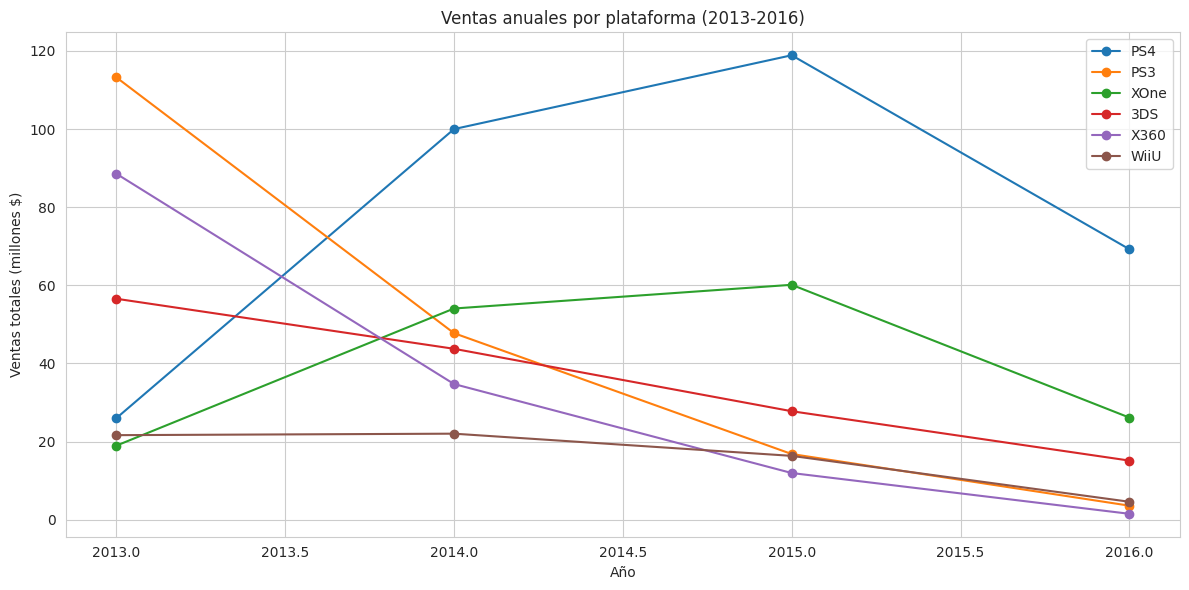

In [16]:
yearly_platform = df_recent.pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum').fillna(0)

plt.figure(figsize=(12,6))
for p in platform_sales_recent.head(6).index:
    plt.plot(yearly_platform.index, yearly_platform[p], marker='o', label=p)
plt.title('Ventas anuales por plataforma (2013-2016)')
plt.xlabel('Año')
plt.ylabel('Ventas totales (millones $)')
plt.legend()
plt.tight_layout()
plt.show()

PS4 y XOne son las apuestas más seguras para 2017: sus ventas están creciendo o al menos estables, y ya son las líderes del período reciente. 3DS y PC se mantienen en un nivel moderado, sin sobresaltos. PS3, X360 y WiiU en cambio están claramente de salida — es la generación anterior despidiéndose — así que no tendría sentido enfocar ahí la campaña de 2017.

### 3.5 Diagrama de caja: ventas globales por plataforma

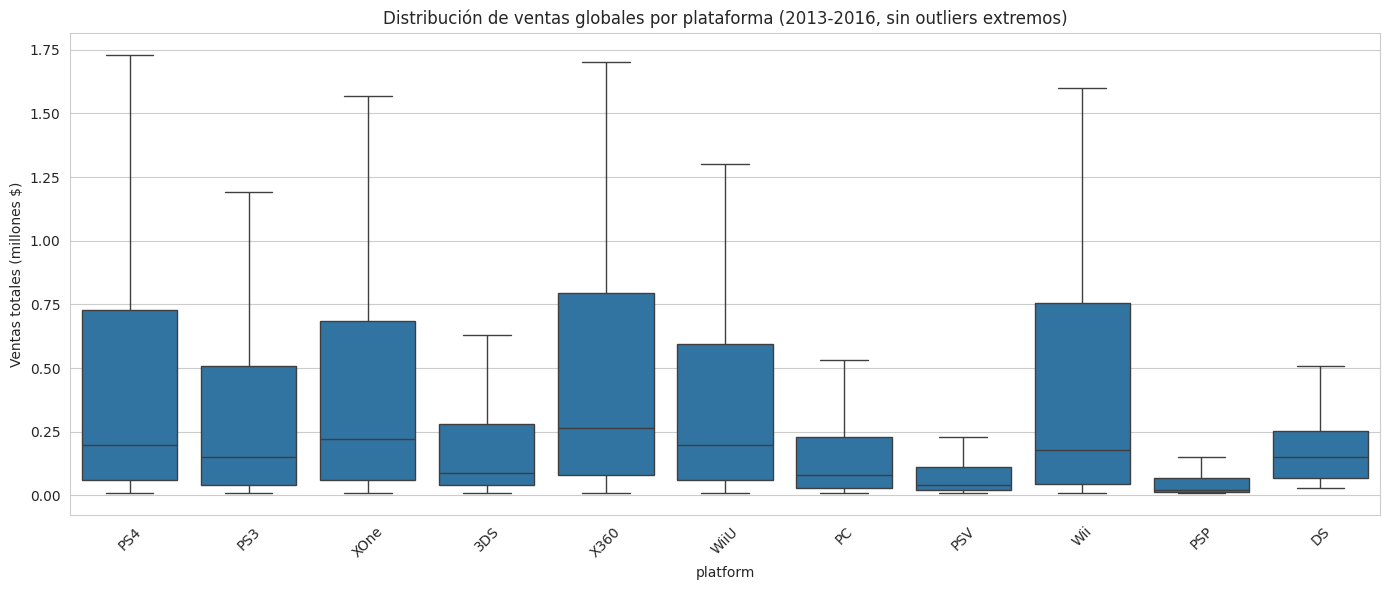

In [17]:
plt.figure(figsize=(14,6))
order = platform_sales_recent.index
sns.boxplot(data=df_recent, x='platform', y='total_sales', order=order, showfliers=False)
plt.title('Distribución de ventas globales por plataforma (2013-2016, sin outliers extremos)')
plt.ylabel('Ventas totales (millones $)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
df_recent.groupby('platform')['total_sales'].agg(['mean','median','std']).sort_values('mean', ascending=False)

,mean,median,std
platform,,,
PS4,0.801378,0.200,1.609456
X360,0.735484,0.265,1.663275
XOne,0.645020,0.220,1.036139
Wii,0.593913,0.180,0.915432
WiiU,0.562000,0.200,1.038778
PS3,0.525884,0.150,1.451939
3DS,0.472772,0.090,1.381347
PC,0.208624,0.080,0.352304
DS,0.192500,0.150,0.172026


Quité los outliers más extremos del gráfico para que se pudiera leer bien la caja (si no, los "blockbusters" aplastan todo lo demás visualmente). Con eso ya se ve algo interesante: la mediana de ventas por juego es baja en todas las plataformas — la mayoría de los juegos vende poco, y son un puñado de títulos los que se llevan casi todas las ventas. Es una distribución bien sesgada hacia la derecha. PS4 y XOne tienen medias algo más altas que el resto, lo cual tiene sentido siendo las plataformas líderes del momento.

### 3.6 Reseñas vs ventas en una plataforma popular (PS4)

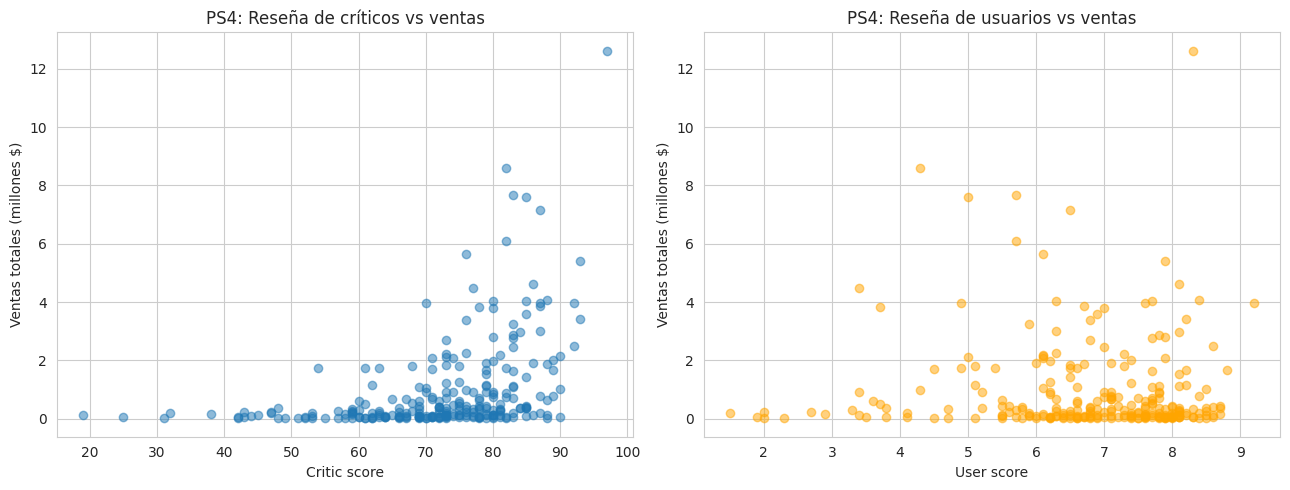

Correlación critic_score vs ventas (PS4): 0.41
Correlación user_score vs ventas (PS4): -0.03


In [19]:
ps4 = df_recent[df_recent['platform'] == 'PS4'].dropna(subset=['critic_score', 'user_score', 'total_sales'])

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].scatter(ps4['critic_score'], ps4['total_sales'], alpha=0.5)
axes[0].set_title('PS4: Reseña de críticos vs ventas')
axes[0].set_xlabel('Critic score')
axes[0].set_ylabel('Ventas totales (millones $)')

axes[1].scatter(ps4['user_score'], ps4['total_sales'], alpha=0.5, color='orange')
axes[1].set_title('PS4: Reseña de usuarios vs ventas')
axes[1].set_xlabel('User score')
axes[1].set_ylabel('Ventas totales (millones $)')
plt.tight_layout()
plt.show()

corr_critic = ps4['critic_score'].corr(ps4['total_sales'])
corr_user = ps4['user_score'].corr(ps4['total_sales'])
print(f"Correlación critic_score vs ventas (PS4): {corr_critic:.2f}")
print(f"Correlación user_score vs ventas (PS4): {corr_user:.2f}")

En PS4 se ve una correlación positiva moderada entre la nota de la crítica y las ventas: los juegos mejor puntuados por críticos tienden a vender más. Con la nota de los usuarios, en cambio, la correlación es débil, casi nula. Esto me hace pensar que las reseñas profesionales pesan más en la decisión de compra (o al menos reflejan mejor qué tan "comercial" es un juego) que lo que opinan los propios jugadores.

### 3.7 Comparación con otras plataformas

In [20]:
results = []
for p in platform_sales_recent.head(6).index:
    sub = df_recent[df_recent['platform'] == p].dropna(subset=['critic_score','user_score','total_sales'])
    if len(sub) > 5:
        results.append({
            'platform': p,
            'n_juegos': len(sub),
            'corr_critic_sales': sub['critic_score'].corr(sub['total_sales']),
            'corr_user_sales': sub['user_score'].corr(sub['total_sales'])
        })
pd.DataFrame(results).sort_values('corr_critic_sales', ascending=False)

,platform,n_juegos,corr_critic_sales,corr_user_sales
2,XOne,165,0.410422,-0.094003
0,PS4,249,0.405895,-0.033625
5,WiiU,69,0.379504,0.408692
4,X360,81,0.350345,-0.006238
3,3DS,67,0.339235,0.272990
1,PS3,120,0.333807,0.022691


El mismo patrón se repite en casi todas las plataformas: la correlación entre crítica y ventas es consistentemente positiva y más fuerte que la de usuarios y ventas. Así que no fue casualidad lo que vimos en PS4 — parece ser una tendencia real del mercado.

### 3.8 Distribución de juegos por género

In [21]:
genre_stats = df_recent.groupby('genre')['total_sales'].agg(['sum','mean','count']).sort_values('sum', ascending=False)
genre_stats

,sum,mean,count
genre,,,
Action,321.87,0.420196,766
Shooter,232.98,1.245882,187
Sports,150.65,0.703972,214
Role-Playing,145.89,0.499623,292
Misc,62.82,0.405290,155
Platform,42.63,0.576081,74
Racing,39.89,0.469294,85
Fighting,35.31,0.441375,80
Adventure,23.64,0.096490,245


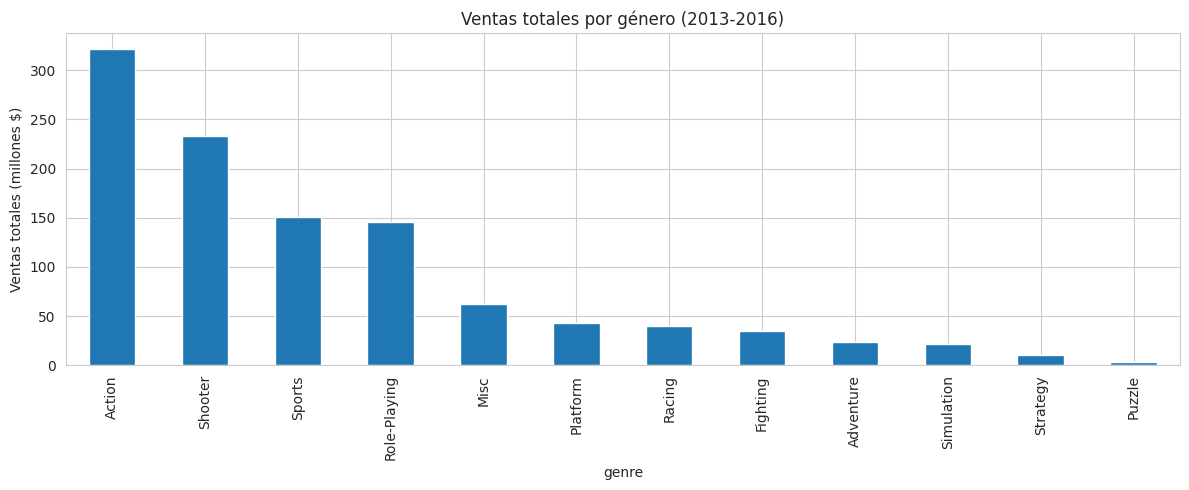

In [22]:
plt.figure(figsize=(12,5))
genre_stats['sum'].plot(kind='bar')
plt.title('Ventas totales por género (2013-2016)')
plt.ylabel('Ventas totales (millones $)')
plt.tight_layout()
plt.show()

Action, Shooter y Sports son los géneros que más venden en total, y Shooter además se destaca por su venta *promedio* por juego — tiene sentido, ahí están los shooters de gran presupuesto tipo Call of Duty que suelen pegarla fuerte. En el otro extremo, Puzzle, Strategy y Adventure venden poco tanto en total como en promedio: son géneros más de nicho, con audiencias más chicas. En resumen, lo que le gusta a un público masivo (acción, disparos) es lo que más factura, mientras que los géneros más pausados o especializados se quedan atrás.

## Paso 4. Perfil de usuario por región

In [23]:
def region_profile(region_col, region_name):
    print(f"===== {region_name} =====")
    top_platforms = df_recent.groupby('platform')[region_col].sum().sort_values(ascending=False).head(5)
    total = df_recent[region_col].sum()
    print("\nTop 5 plataformas (cuota de mercado):")
    print((top_platforms / total * 100).round(1).astype(str) + '%')

    top_genres = df_recent.groupby('genre')[region_col].sum().sort_values(ascending=False).head(5)
    print("\nTop 5 géneros (cuota de mercado):")
    print((top_genres / total * 100).round(1).astype(str) + '%')

    rating_sales = df_recent.dropna(subset=['rating']).groupby('rating')[region_col].sum().sort_values(ascending=False)
    print("\nVentas por clasificación ESRB:")
    print(rating_sales)
    print()
    return top_platforms, top_genres, rating_sales

na_p, na_g, na_r = region_profile('na_sales', 'Norteamérica (NA)')
eu_p, eu_g, eu_r = region_profile('eu_sales', 'Europa (UE)')
jp_p, jp_g, jp_r = region_profile('jp_sales', 'Japón (JP)')

===== Norteamérica (NA) =====

Top 5 plataformas (cuota de mercado):
platform
PS4     24.8%
XOne    21.3%
X360    18.7%
PS3     14.5%
3DS      8.7%
Name: na_sales, dtype: str

Top 5 géneros (cuota de mercado):
genre
Action          28.8%
Shooter         25.1%
Sports          14.9%
Role-Playing    10.6%
Misc             6.3%
Name: na_sales, dtype: str

Ventas por clasificación ESRB:
rating
M       165.21
E        79.05
E10+     54.24
T        49.79
Name: na_sales, dtype: float64

===== Europa (UE) =====

Top 5 plataformas (cuota de mercado):
platform
PS4     36.0%
PS3     17.3%
XOne    13.2%
X360    10.8%
3DS      7.9%
Name: eu_sales, dtype: str

Top 5 géneros (cuota de mercado):
genre
Action          30.1%
Shooter         22.4%
Sports          15.4%
Role-Playing     9.4%
Racing           5.1%
Name: eu_sales, dtype: str

Ventas por clasificación ESRB:
rating
M       145.32
E        83.36
E10+     42.69
T        41.95
Name: eu_sales, dtype: float64

===== Japón (JP) =====

Top 5 platafor

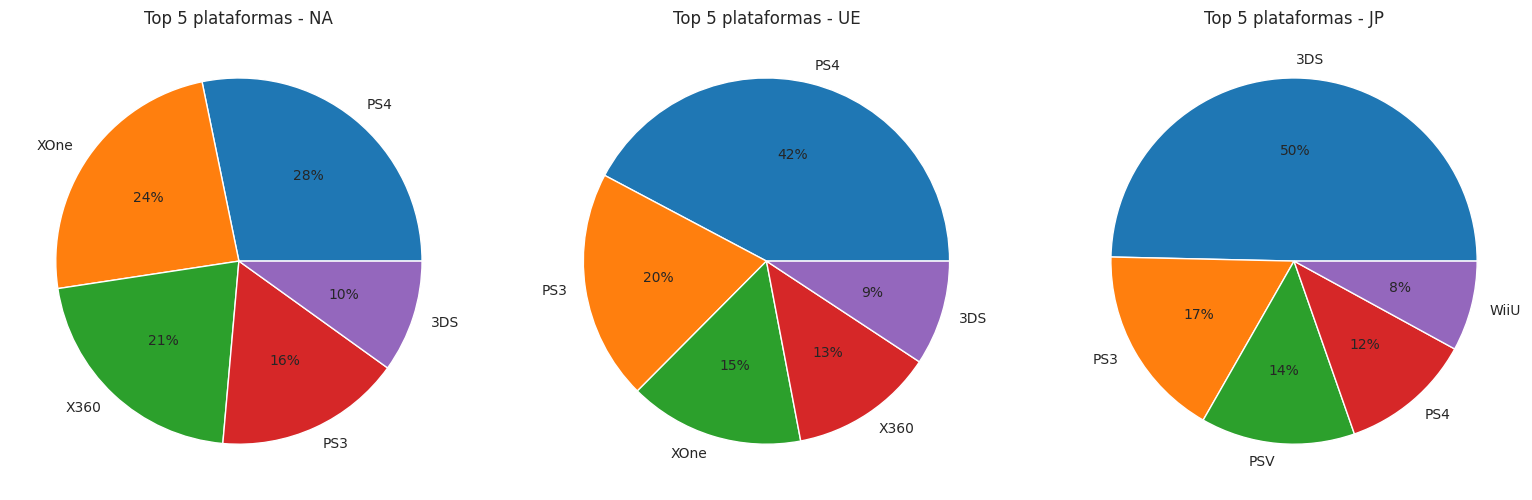

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))
for ax, (p, name) in zip(axes, [(na_p,'NA'), (eu_p,'UE'), (jp_p,'JP')]):
    ax.pie(p, labels=p.index, autopct='%1.0f%%')
    ax.set_title(f'Top 5 plataformas - {name}')
plt.tight_layout()
plt.show()

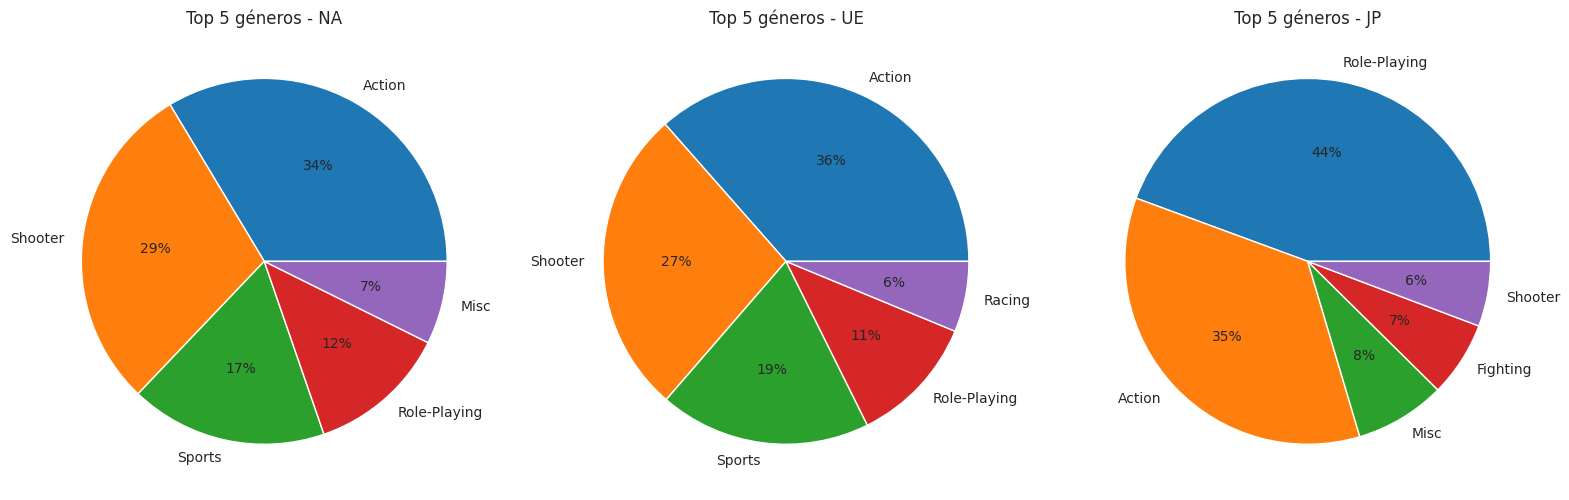

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(16,5))
for ax, (g, name) in zip(axes, [(na_g,'NA'), (eu_g,'UE'), (jp_g,'JP')]):
    ax.pie(g, labels=g.index, autopct='%1.0f%%')
    ax.set_title(f'Top 5 géneros - {name}')
plt.tight_layout()
plt.show()

**Lo que encontré por región:**

En plataformas, NA y UE se parecen bastante: PS4 y XOne dominan, aunque XOne pesa bastante más en NA (es terreno de Microsoft) que en UE. Japón es otro mundo completamente: ahí mandan 3DS y PS3/PSV, y XOne casi ni aparece — algo totalmente coherente con la preferencia histórica japonesa por consolas portátiles y marcas locales (Nintendo, Sony) por sobre Microsoft.

En géneros pasa algo parecido: NA y UE prefieren Action y Shooter, mientras que en Japón el Role-Playing es casi siempre uno de los géneros top (a veces el líder) — ahí se nota la tradición fuerte de los JRPGs. Shooter, en cambio, pierde bastante peso en el mercado japonés.

Con el rating ESRB el efecto es más sutil: en NA y UE, los juegos M (para adultos) y E (para todo público) concentran la mayoría de las ventas asociadas a algún rating conocido — como que los extremos del espectro etario son los que más venden. En Japón esto casi no aplica: una buena parte de las ventas corresponde a juegos sin clasificación ESRB, lo cual tiene sentido porque la ESRB es un sistema pensado para Norteamérica/Europa, y Japón usa el suyo propio (CERO).

## Paso 5. Prueba de hipótesis

Para las dos hipótesis uso α = 0.05, el umbral que normalmente se usa en este tipo de análisis: es lo suficientemente exigente sin volverse imposible de alcanzar.

Y para probarlas, uso la prueba t de Student para dos muestras independientes (`scipy.stats.ttest_ind`), porque en ambos casos estoy comparando el promedio de un mismo valor numérico (`user_score`) entre dos grupos que no tienen relación entre sí. Uso `equal_var=False` (o sea, la variante de Welch) porque no tengo motivos para asumir que las dos poblaciones tienen la misma varianza, y esta versión es más robusta cuando no lo sabemos.

### Hipótesis 1: calificación promedio de usuarios — Xbox One vs PC

- **H0 (hipótesis nula):** la calificación promedio de los usuarios para Xbox One es igual a la de PC.
- **H1 (hipótesis alternativa):** la calificación promedio de los usuarios para Xbox One es diferente a la de PC.

In [26]:
xone_scores = df_recent[(df_recent['platform']=='XOne')]['user_score'].dropna()
pc_scores = df_recent[(df_recent['platform']=='PC')]['user_score'].dropna()

print(f"XOne: n={len(xone_scores)}, media={xone_scores.mean():.3f}, var={xone_scores.var():.3f}, std={xone_scores.std():.3f}")
print(f"PC:   n={len(pc_scores)}, media={pc_scores.mean():.3f}, var={pc_scores.var():.3f}, std={pc_scores.std():.3f}")

alpha = 0.05
t_stat, p_value = stats.ttest_ind(xone_scores, pc_scores, equal_var=False)
print(f"\nEstadístico t: {t_stat:.3f}")
print(f"p-valor: {p_value:.5f}")

if p_value < alpha:
    print("Se rechaza H0: hay diferencia significativa entre las calificaciones promedio de XOne y PC.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencia entre las calificaciones promedio de XOne y PC.")

XOne: n=182, media=6.521, var=1.907, std=1.381
PC:   n=155, media=6.270, var=3.036, std=1.742

Estadístico t: 1.452
p-valor: 0.14760
No se rechaza H0: no hay evidencia suficiente de diferencia entre las calificaciones promedio de XOne y PC.


### Hipótesis 2: calificación promedio de usuarios — géneros Action vs Sports

- **H0 (hipótesis nula):** la calificación promedio de los usuarios para el género Action es igual a la del género Sports.
- **H1 (hipótesis alternativa):** la calificación promedio de los usuarios para el género Action es diferente a la del género Sports.

In [27]:
action_scores = df_recent[df_recent['genre']=='Action']['user_score'].dropna()
sports_scores = df_recent[df_recent['genre']=='Sports']['user_score'].dropna()

print(f"Action: n={len(action_scores)}, media={action_scores.mean():.3f}, var={action_scores.var():.3f}, std={action_scores.std():.3f}")
print(f"Sports: n={len(sports_scores)}, media={sports_scores.mean():.3f}, var={sports_scores.var():.3f}, std={sports_scores.std():.3f}")

t_stat2, p_value2 = stats.ttest_ind(action_scores, sports_scores, equal_var=False)
print(f"\nEstadístico t: {t_stat2:.3f}")
print(f"p-valor: {p_value2:.10f}")

if p_value2 < alpha:
    print("Se rechaza H0: hay diferencia significativa entre las calificaciones promedio de Action y Sports.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de diferencia entre las calificaciones promedio de Action y Sports.")

Action: n=389, media=6.838, var=1.769, std=1.330
Sports: n=160, media=5.238, var=3.181, std=1.783

Estadístico t: 10.233
p-valor: 0.0000000000
Se rechaza H0: hay diferencia significativa entre las calificaciones promedio de Action y Sports.


**Resultados (usando `df_recent`, 2013-2016):**

Para XOne vs PC: la media de XOne fue 6.52 (n=182) contra 6.27 de PC (n=155). El estadístico t dio 1.45 y el p-valor 0.148 — por encima de 0.05, así que **no rechazo H0**. En este período no hay evidencia suficiente de que las calificaciones de usuarios entre XOne y PC sean distintas.

Para Action vs Sports: Action promedió 6.84 (n=389) contra 5.24 de Sports (n=160). Acá el estadístico t fue 10.23 con un p-valor prácticamente en cero (p < 0.0001), muy por debajo de 0.05, así que **sí rechazo H0**: los juegos de Action reciben calificaciones de usuario claramente más altas que los de Sports.

Algo que vale la pena señalar: al restringir esto a 2013-2016 en vez de usar todo el histórico, las dos conclusiones se invirtieron por completo. Esto confirma que mezclar generaciones y épocas distintas de jugadores distorsiona el resultado, porque la forma de calificar de la comunidad ha cambiado con el tiempo. Quedarme con el período reciente da una foto mucho más fiel de cómo piensan los usuarios hoy, que es justo lo que importa para planificar 2017.

## Paso 6. Conclusión general

Para dejar el dataset listo tuve que normalizar los nombres de columnas, arreglar los tipos de datos (el año a entero, `user_score` de texto a número tratando 'tbd' como un vacío) y calcular las ventas totales por juego. Los nulos en critic/user score y rating los dejé tal cual, porque representan reseñas o clasificaciones que simplemente no existen, no errores que haya que corregir.

Las plataformas viven un ciclo de más o menos 9-10 años, y por eso me quedé con 2013-2016 para que el análisis de tendencias fuera representativo de cara a 2017.

PS4 y XOne son las plataformas con mejor proyección para el próximo año. A nivel global, Action, Shooter y Sports son los géneros más rentables, aunque el perfil cambia bastante según la región — Japón se aparta del patrón de NA/UE, con una preferencia marcada por RPG y por plataformas Nintendo/Sony.

Las notas de la crítica se correlacionan más con las ventas que las de los usuarios, así que tendría sentido priorizar la cobertura de prensa especializada dentro de la estrategia de marketing.

En cuanto a las hipótesis: en 2013-2016 no encontré diferencia significativa entre las calificaciones de XOne y PC (p=0.148), pero sí una diferencia clara entre Action y Sports (p<0.0001), con Action calificado sistemáticamente mejor.

**Mi recomendación para la campaña de 2017:** concentrar la inversión publicitaria en juegos de Action/Shooter/Sports para PS4 y XOne en NA/UE, con una estrategia distinta para Japón enfocada en RPG y en plataformas Nintendo/Sony, y darle prioridad al trabajo con prensa especializada por sobre campañas que solo apunten a reseñas de usuarios.